<a href="https://colab.research.google.com/github/tarannzaki/Labs-and-Projects-in-AIML-Training-Program/blob/main/AIML_%E2%80%93_Module_3_Lab_1_Loss_Functions_and_Gradient_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Module 3
## Lab 1: Gradient Descent

# Gradient Descent: A Quick Recap

We introduced **Gradient Descent** as a method to find the minimum of a loss function. It is the core optimization algorithm that powers a vast majority of **Machine Learning** and **Deep Learning** models.

---

### A Quick Recap of the Algorithm

The core idea of **Gradient Descent** is to iteratively take steps in the direction of the steepest descent of a function (our loss function) to find its minimum.

1. Start with a random initialization of the solution (model parameters or weights).
2. Incrementally change the solution by moving in the direction of the **negative gradient** of the loss function.
3. Repeat the previous step until some convergence criteria is met.

---

The key update equation for a weight or parameter ($w$) is:

$$
w_{k+1} \leftarrow w_k - \eta \nabla J
$$

Where:
- $w_k$ is the current weight.
- $\eta$ is the **learning rate**.
- $\nabla J$ is the **gradient of the loss function** $J$.


In this lab, we will discuss stochastic gradient descent, mini-batch gradient descent and batch gradient descent.


### Setting up the Environment and Data

First, let's import the necessary libraries and set a random seed for reproducibility.

In [18]:
import numpy as np
import matplotlib.pyplot as plt

In [19]:
np.random.seed(42)

## Creating the Data

We'll generate some synthetic data that follows a **linear pattern**. Our true linear equation will be:

$$
y = 4 + 3x
$$

We will also add some **random noise** to the y values to simulate real-world data, which is rarely perfect.

Let's generate the data with:
- `y0 = 4` (intercept)
- `y1 = 3` (slope)

and add some noise to the data.


In [20]:
# We are creating data based on the equation y = 4 + 3x + noise

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

Here, np.random.rand(100, 1) creates 100 random numbers between 0 and 1. Multiplying by 2 scales this to be between 0 and 2. np.random.randn(100, 1) adds Gaussian noise (random fluctuations) to our y values.

Let's also plot the data we just created

Text(0, 0.5, 'y')

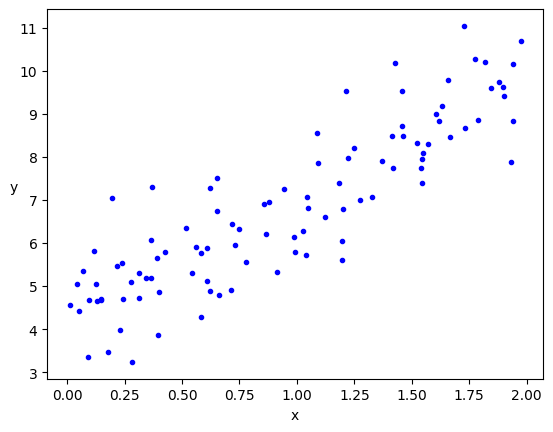

In [21]:
plt.plot(X, y, 'b.')
plt.xlabel('x')
plt.ylabel('y', rotation=0)

Our goal is to use Gradient Descent to find the original parameters (intercept = 4, slope = 3) just by looking at this scattered data.

## The Cost Function for Linear Regression

Before we can optimize, we need to define how we measure error. For **Linear Regression**, we use the **Mean Squared Error (MSE)** cost function. It measures the average squared difference between the model's predictions and the actual values.

The equation for the MSE cost function $J$ is:

$$
J(\theta) = \frac{1}{2m}  \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2
$$

Where:
- $m$ is the number of training examples.
- $\theta$ is our vector of model parameters (in our case, the intercept and the slope).
- $h_\theta(x^{(i)})$ is the prediction for the $i$-th example.
- $y^{(i)}$ is the true label for the $i$-th example.

The $\frac{1}{2}$ is included for convenience, as it simplifies the derivative calculation.


In [22]:
def cal_cost(y_pred, X, y):
    '''
    Calculates the cost for given X and Y.
    y_pred = Vector of y_preds
    X = Row of X's np.zeros((2, j))
    y = Actual y's np.zeros((2, 1))

    where:
        j is the no of features
    '''

    m = len(y)

    predictions = X.dot(y_pred)
    cost = (1 / (2 * m)) * np.sum(np.square(predictions - y))

    return cost

## The Gradient of the Cost Function

To use **Gradient Descent**, we need the partial derivatives of the cost function with respect to each parameter \(\theta_j\).

The general form of the gradient for **Linear Regression** is:

$$
\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}
$$

For our problem with one feature \(x\) and an intercept, we have two parameters: \(\theta_0\) (intercept) and \(\theta_1\) (slope). The updates will be:

$$
\theta_0 := \theta_0 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)
$$

$$
\theta_1 := \theta_1 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) \cdot x_1^{(i)}
$$

This can be written in a compact, **vectorized form**:

$$
\nabla J(\theta) = \frac{1}{m} X^T (X\theta - y)
$$


### Variant 1: Batch Gradient Descent

**Batch Gradient Descent** is the simplest variant. In each step, it calculates the gradient using the **entire training dataset**.

**Pros:**
- The convergence path is smooth and stable because the gradient is a true average over all data.

**Cons:**
- It is very slow and computationally expensive for large datasets.


In [23]:
def gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=100):
    '''
    X = Matrix of X with added bias units
    y = Vector of Y
    y_pred = Vector of parameters (theta)
    learning_rate
    iterations = no of iterations

    Returns the final y_pred vector and array of cost history over no of iterations
    '''
    m = len(y)
    cost_history = np.zeros(iterations)
    y_pred_history = np.zeros((iterations, 2))

    for it in range(iterations):
        # Calculate prediction: prediction = X . theta
        prediction = np.dot(X, y_pred)

        # Update parameters: theta = theta - (1/m) * learning_rate * (X^T . (prediction - y))
        y_pred = y_pred - (1 / m) * learning_rate * (X.T.dot((prediction - y)))

        y_pred_history[it,:] = y_pred.T
        cost_history[it]  = cal_cost(y_pred, X, y)

    return y_pred, cost_history, y_pred_history

### Running Batch Gradient Descent

Let's run this for **1000 iterations** with a learning rate of **0.01**. We start with a random guess for our parameters (`y_pred`).

**Our model** is:
$$
y = \theta_0 + \theta_1 x
$$

**A crucial step:**
To handle the intercept term $\theta_0$ using matrix multiplication, we add a "dummy" feature $x_0 = 1$ to all our input samples. This is known as the **bias trick**.


In [24]:
lr = 0.01
n_iter = 1000

y_pred = np.random.randn(2,1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history, y_pred_history = gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 3.903
y_pred[1]: 3.046
Final error: 0.418


The learned parameters (3.903, 3.046) are very close to our original true values (4, 3)!

### Visualizing the Loss

Let's plot the error at each iteration. This is our "descent down the mountain".

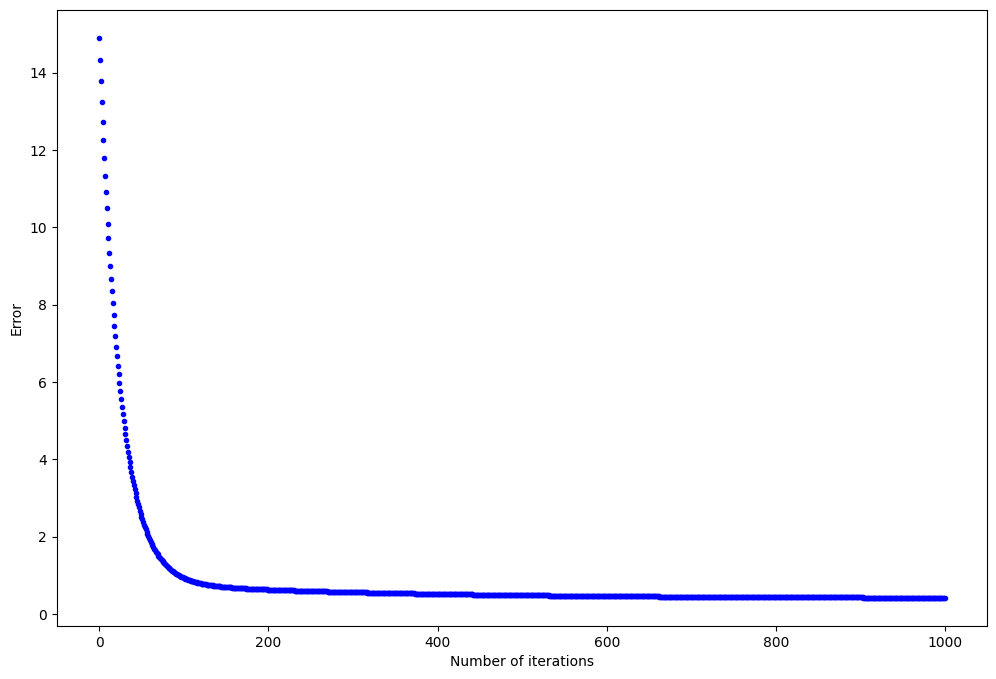

In [25]:
fig, ax = plt.subplots(figsize=(12,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')

ax.plot(range(n_iter), cost_history, 'b.')

Zooming in on the first 200 iterations shows how the error drops rapidly at first and then slows down as it approaches the minimum.

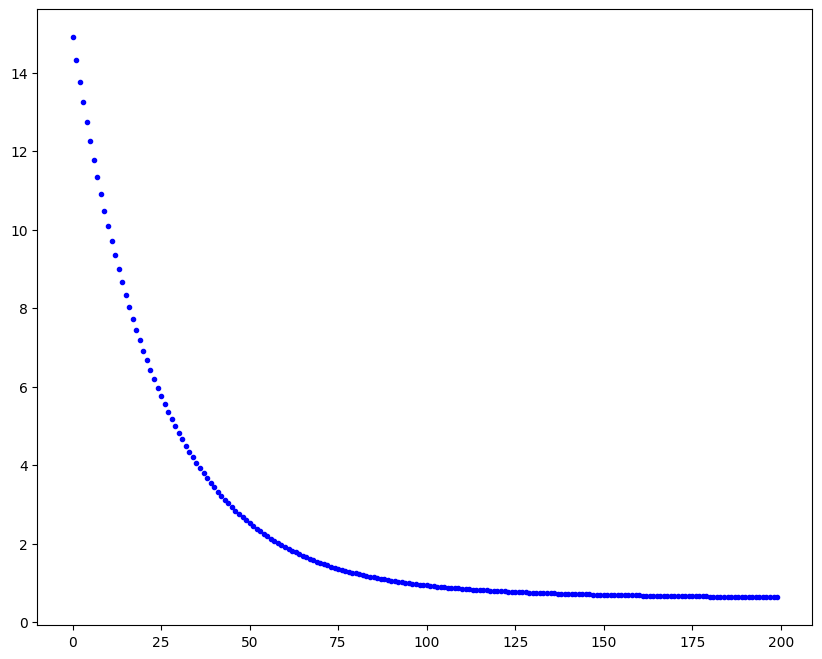

In [26]:
fig,ax = plt.subplots(figsize=(10,8))
ax.plot(range(200), cost_history[:200], 'b.')

The smooth curve is characteristic of Batch Gradient Descent.

### Variant 2: Stochastic Gradient Descent (SGD)

**Batch GD** is inefficient for large datasets. **SGD** addresses this by taking a gradient step based on **only one randomly chosen training example at a time**.

**Pros:**
- Extremely fast per step.
- Can help escape shallow local minima due to its random nature.

**Cons:**
- The path to the minimum is very noisy and erratic.
- It never truly "settles" at the minimum but bounces around it.


In [27]:
def stocashtic_gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=10):
    '''
    X = Matrix of X with added bias units
    y = Vector of Y
    y_pred = Vector of y_pred np.random.randn(j,1)
    learning_rate
    iterations = no of iterations

    Returns the final y_pred vector and array of cost history over no of iterations
    '''

    m = len(y)
    cost_history = np.zeros(iterations)

    for it in range(iterations):
        cost = 0.0

        for i in range(m):
            rand_ind = np.random.randint(0,m)
            X_i = X[rand_ind, :].reshape(1, X.shape[1])
            y_i = y[rand_ind].reshape(1,1)
            prediction = np.dot(X_i, y_pred)

            y_pred = y_pred - (1 / m) * learning_rate *(X_i.T.dot((prediction - y_i)))
            cost += cal_cost(y_pred, X_i, y_i)

        cost_history[it]  = cost

    return y_pred, cost_history

Let's run SGD. Note that it requires a much higher learning rate and fewer epochs (passes over the data) to converge.

In [28]:
lr = 0.5
n_iter = 50
y_pred = np.random.randn(2, 1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history = stocashtic_gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.121
y_pred[1]: 2.755
Final error: 41.313


Again, the parameters are close to the true values, but notice the final error is higher and the parameters are slightly less accurate. This is due to the noisy nature of SGD.


### Visualizing the Loss

The loss curve for SGD is much more erratic.

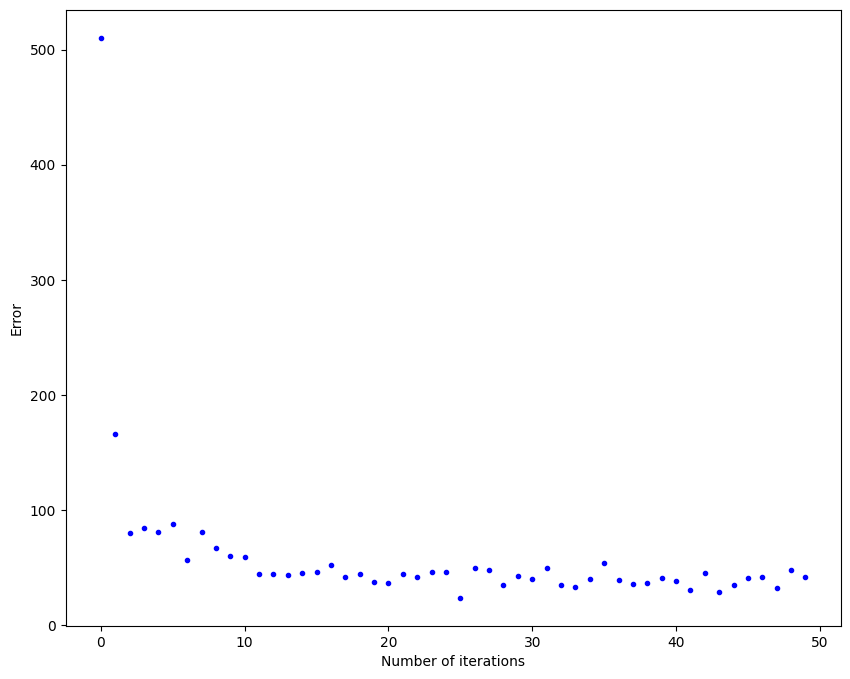

In [29]:
fig, ax = plt.subplots(figsize=(10,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')
y_pred = np.random.randn(2,1)

ax.plot(range(n_iter), cost_history, 'b.')

### Variant 3: Mini-Batch Gradient Descent

**Mini-Batch GD** is the happy medium. It computes the gradient on a small, random subset of the data called a **mini-batch**.

**Pros:**
- A good balance between the stability of Batch GD and the speed of SGD.
- Allows for vectorized implementation, making it very efficient on modern hardware (like GPUs).

**Cons:**
- Introduces a new hyperparameter: the `batch_size`.

This is the **most common variant** used in deep learning today.


In [30]:
def minibatch_gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=10, batch_size=20):
    '''
    X = Matrix of X without added bias units
    y = Vector of Y
    y_pred = Vector of y_preds np.random.randn(j, 1)
    learning_rate
    iterations = no of iterations

    Returns the final theta vector and array of cost history over no of iterations
    '''

    m = len(y)
    cost_history = np.zeros(iterations)
    n_batches = int(m / batch_size)

    for it in range(iterations):
        cost = 0.0
        indices = np.random.permutation(m)
        X = X[indices]
        y = y[indices]

        for i in range(0, m, batch_size):
            X_i = X[i: i + batch_size]
            y_i = y[i: i + batch_size]

            X_i = np.c_[np.ones(len(X_i)), X_i]
            prediction = np.dot(X_i, y_pred)

            y_pred = y_pred - (1 / m) * learning_rate * (X_i.T.dot((prediction - y_i)))
            cost += cal_cost(y_pred, X_i, y_i)

        cost_history[it]  = cost

    return y_pred, cost_history

Let's run it.

In [56]:
lr = 0.1
n_iter = 200
y_pred = np.random.randn(2,1)
y_pred, cost_history = minibatch_gradient_descent(
    X, y, y_pred, lr, n_iter, batch_size=20
)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.142
y_pred[1]: 2.836
Final error: 2.017


### Visualizing the Loss

The loss curve is less noisy than SGD but not as smooth as Batch GD.

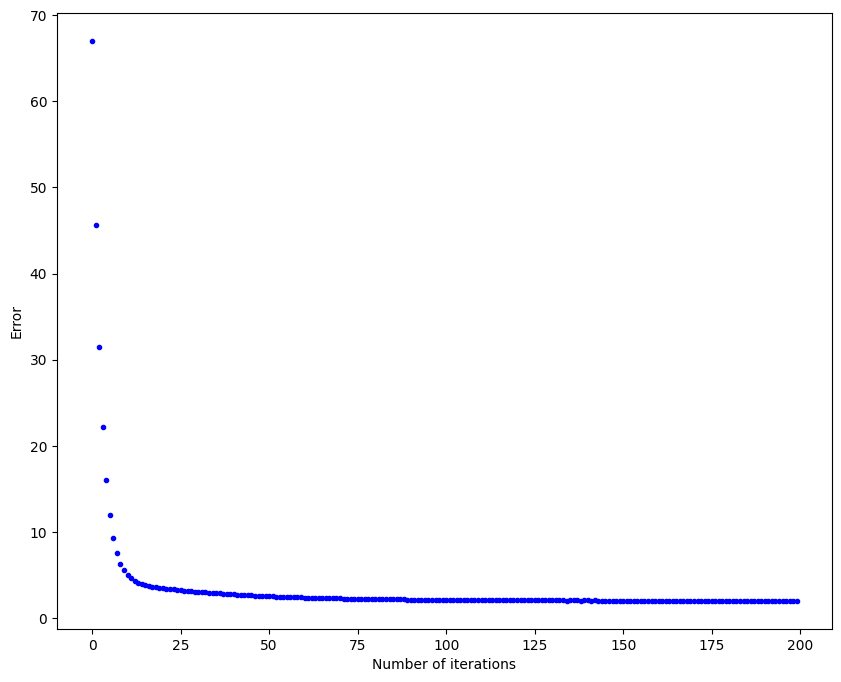

In [32]:
fig, ax = plt.subplots(figsize=(10,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')
y_pred = np.random.randn(2,1)

ax.plot(range(n_iter), cost_history, 'b.')

### Visual Comparison of the Learned Models

Let's re-run all three algorithms and plot their final learned lines on the original data. This will give us a better intuition for how they perform.

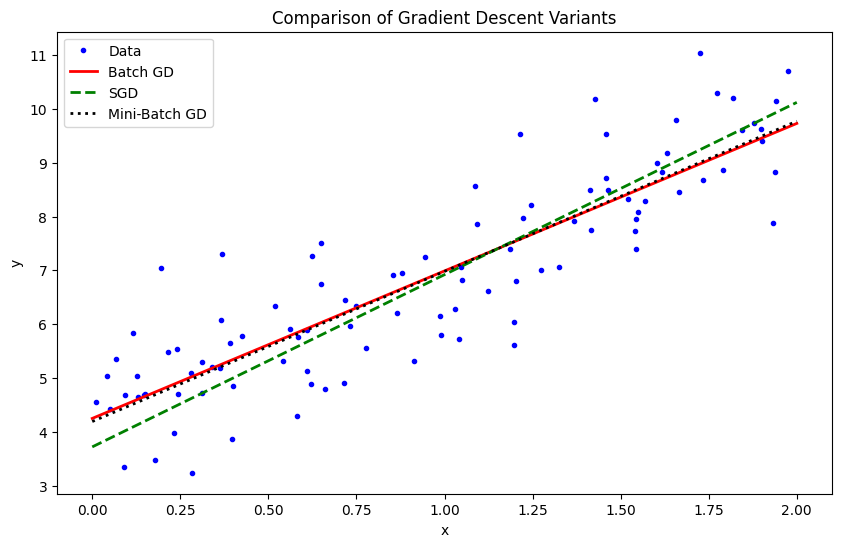

In [33]:
# Rerun all three for comparison
# Batch
lr_batch = 0.1
n_iter_batch = 200
y_pred_batch_final, _, _ = gradient_descent(X_b, y, np.random.randn(2,1), lr_batch, n_iter_batch)

# SGD
lr_sgd = 0.05
n_iter_sgd = 200
y_pred_sgd_final, _ = stocashtic_gradient_descent(X_b, y, np.random.randn(2,1), lr_sgd, n_iter_sgd)

# Mini-Batch
lr_mini = 0.1
n_iter_mini = 200
y_pred_mini_final, _ = minibatch_gradient_descent(X, y, np.random.randn(2,1), lr_mini, n_iter_mini)


# Plotting
plt.figure(figsize=(10, 6))
plt.plot(X, y, 'b.', label='Data')
# Create a set of X values for plotting the lines
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
# Get predictions for the lines
y_predict_batch = X_new_b.dot(y_pred_batch_final)
y_predict_sgd = X_new_b.dot(y_pred_sgd_final)
y_predict_mini = X_new_b.dot(y_pred_mini_final)

plt.plot(X_new, y_predict_batch, 'r-', linewidth=2, label='Batch GD')
plt.plot(X_new, y_predict_sgd, 'g--', linewidth=2, label='SGD')
plt.plot(X_new, y_predict_mini, 'k:', linewidth=2, label='Mini-Batch GD')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Comparison of Gradient Descent Variants')
plt.legend()
plt.show()

As you can see, all three methods find a very good fit to the data. While their training dynamics (the loss curves) are very different, they all achieve the same goal.

### Things to Try Out

1. **Change batch size in mini-batch gradient descent:**
   Try a small size (e.g., `2`) and a large size (e.g., `80`). How does the loss curve change? What happens when the batch size equals the total number of samples?

2. **Test on real datasets:**
   Use a dataset from `sklearn.datasets`, like the **Boston Housing** or **Diabetes** datasets, and see how each variant performs.

3. **Compare learning rates:**
   Test the effects of changing the learning rate. Try a very high and a very low learning rate for each of the three variants. Which one is most sensitive to the learning rate?

4. **Implement a learning rate schedule for SGD:**
   Instead of a fixed learning rate, make it decrease over time (e.g., `lr = initial_lr / (epoch + 1)`). How does this affect the final error and the stability of the loss curve?


In [37]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
X_real = diabetes.data
y_real = diabetes.target

print("Dataset shape:", X_real.shape)
print("Target shape:", y_real.shape)

Dataset shape: (442, 10)
Target shape: (442,)


In [38]:
# Use BMI as the single input feature
X_real = diabetes.data[:, [2]]
y_real = diabetes.target.reshape(-1, 1)

# Add the intercept column
X_real_b = np.c_[np.ones((len(X_real), 1)), X_real]

print("Input shape:", X_real_b.shape)
print("Target shape:", y_real.shape)

Input shape: (442, 2)
Target shape: (442, 1)


In [39]:
lr = 0.01
n_iter = 1000

y_pred_real = np.random.randn(2, 1)

y_pred_real, cost_history_real, _ = gradient_descent(
    X_real_b, y_real, y_pred_real, lr, n_iter
)

print("Intercept:", y_pred_real[0][0])
print("BMI coefficient:", y_pred_real[1][0])
print("Final cost:", cost_history_real[-1])

Intercept: 152.12691850453024
BMI coefficient: 21.284655710884593
Final cost: 2919.73458685826


In [42]:
lr = 0.01
n_iter = 1000

y_pred_real_sgd = np.random.randn(2, 1)

y_pred_real_sgd, cost_history_real_sgd = stocashtic_gradient_descent(
    X_real_b, y_real, y_pred_real_sgd, lr, n_iter
)

print("Intercept:", y_pred_real_sgd[0][0])
print("BMI coefficient:", y_pred_real_sgd[1][0])
print("Final cost:", cost_history_real_sgd[-1])

Intercept: 152.38586881878524
BMI coefficient: 22.411094809662433
Final cost: 1338349.1747115108


In [44]:
lr = 0.1
n_iter = 200
batch_size = 20

y_pred_real_mini = np.random.randn(2, 1)

y_pred_real_mini, cost_history_real_mini = minibatch_gradient_descent(
    X_real, y_real, y_pred_real_mini,
    learning_rate=lr,
    iterations=n_iter,
    batch_size=batch_size
)

print("Intercept:", y_pred_real_mini[0][0])
print("BMI coefficient:", y_pred_real_mini[1][0])
print("Final cost:", cost_history_real_mini[-1])

Intercept: 152.12256254059588
BMI coefficient: 643.6204512069423
Final cost: 47667.27875235573


In [45]:
lr = 0.001
n_iter = 1000

theta_low = np.random.randn(2, 1)

theta_low, cost_low, _ = gradient_descent(
    X_b, y, theta_low, lr, n_iter
)

print("Parameters:", theta_low.ravel())
print("Final cost:", cost_low[-1])

Parameters: [1.87749524 3.67343663]
Final cost: 1.653574633669319


In [46]:
lr = 0.1
n_iter = 1000

theta_high = np.random.randn(2, 1)

theta_high, cost_high, _ = gradient_descent(
    X_b, y, theta_high, lr, n_iter
)

print("Parameters:", theta_high.ravel())
print("Final cost:", cost_high[-1])

Parameters: [4.21509614 2.7701134 ]
Final cost: 0.40329228198352673


In [47]:
lr = 1.0
n_iter = 1000

theta_very_high = np.random.randn(2, 1)

theta_very_high, cost_very_high, _ = gradient_descent(
    X_b, y, theta_very_high, lr, n_iter
)

print("Parameters:", theta_very_high.ravel())
print("Final cost:", cost_very_high[-1])

Parameters: [-4.22071081e+27 -4.78026120e+27]
Final cost: 4.1987480254037955e+55


In [48]:
lr = 0.001
n_iter = 1000

theta_sgd_low = np.random.randn(2, 1)

theta_sgd_low, cost_sgd_low = stocashtic_gradient_descent(
    X_b, y, theta_sgd_low, lr, n_iter
)

print("Parameters:", theta_sgd_low.ravel())
print("Final cost:", cost_sgd_low[-1])

Parameters: [3.57562261 2.39313241]
Final cost: 72.67436066361816


In [49]:
lr = 0.1
n_iter = 1000

theta_sgd_high = np.random.randn(2, 1)

theta_sgd_high, cost_sgd_high = stocashtic_gradient_descent(
    X_b, y, theta_sgd_high, lr, n_iter
)

print("Parameters:", theta_sgd_high.ravel())
print("Final cost:", cost_sgd_high[-1])

Parameters: [4.22660677 2.75946098]
Final cost: 34.54972164018083


In [50]:
lr = 1.0
n_iter = 1000

theta_sgd_very_high = np.random.randn(2, 1)

theta_sgd_very_high, cost_sgd_very_high = stocashtic_gradient_descent(
    X_b, y, theta_sgd_very_high, lr, n_iter
)

print("Parameters:", theta_sgd_very_high.ravel())
print("Final cost:", cost_sgd_very_high[-1])

Parameters: [4.19258604 2.73873897]
Final cost: 43.59569613293776


In [53]:
lr = 1.0
n_iter = 1000
batch_size = 20

theta_mini_low = np.random.randn(2, 1)

theta_mini_low, cost_mini_low = minibatch_gradient_descent(
    X, y, theta_mini_low,
    learning_rate=lr,
    iterations=n_iter,
    batch_size=batch_size
)

print("Parameters:", theta_mini_low.ravel())
print("Final cost:", cost_mini_low[-1])

Parameters: [4.2320434  2.79180142]
Final cost: 2.0003086712729057


In [54]:
def sgd_with_decay(X, y, y_pred, initial_lr, iterations):
    m = len(y)
    cost_history = np.zeros(iterations)

    for it in range(iterations):
        learning_rate = initial_lr / (it + 1)
        cost = 0.0

        for i in range(m):
            rand_ind = np.random.randint(0, m)
            X_i = X[rand_ind, :].reshape(1, X.shape[1])
            y_i = y[rand_ind].reshape(1, 1)

            prediction = np.dot(X_i, y_pred)

            y_pred = y_pred - (1/m) * learning_rate * (
                X_i.T.dot(prediction - y_i)
            )

            cost += cal_cost(y_pred, X_i, y_i)

        cost_history[it] = cost

    return y_pred, cost_history

In [55]:
initial_lr = 1.0
n_iter = 1000

theta_decay = np.random.randn(2, 1)

theta_decay, cost_decay = sgd_with_decay(
    X_b, y, theta_decay, initial_lr, n_iter
)

print("Parameters:", theta_decay.ravel())
print("Final cost:", cost_decay[-1])

Parameters: [3.8132905  3.12921123]
Final cost: 42.62681944645174


### Experimental Observations and Conclusions

**Experiment 1: Effect of Batch Size**

- A smaller batch size (2) produces more frequent and noisier parameter updates.
- A larger batch size (80) produces more stable updates.
- When the batch size equals the total number of samples (100), Mini-Batch Gradient Descent behaves like Batch Gradient Descent because the entire dataset is used for each update.

**Experiment 2: Testing on a Real Dataset**

The Scikit-learn Diabetes dataset contains 442 samples. BMI was selected as the input feature, and the disease-progression measure was used as the target.

Batch Gradient Descent and SGD produced similar fitted parameters. The Mini-Batch implementation produced an unusually large BMI coefficient. This indicates that the implementation and its update scaling need attention before drawing a reliable comparison.

**Experiment 3: Effect of Learning Rate**

- A very low learning rate resulted in slow convergence.
- A moderate learning rate produced better convergence within the given number of iterations.
- An excessively high learning rate caused Batch Gradient Descent to diverge.
- SGD and Mini-Batch GD showed different behaviours because their updates are stochastic and depend on the selected samples or batches.

**Experiment 4: Learning-Rate Scheduling**

A decreasing learning rate allows larger updates initially and smaller updates later. In our experiment, SGD with a decreasing learning rate produced parameters closer to the true values than ordinary SGD with a constant learning rate of 1.0. It also produced a slightly lower accumulated cost.

**Observation: Learning Rate Scheduling in SGD**

A learning rate that decreases over time can improve the stability of SGD. Initially, larger updates help the algorithm approach the minimum quickly. Later, smaller updates help it make finer adjustments.

In this experiment, SGD with a decreasing learning rate produced parameters closer to the actual values (intercept = 4 and slope = 3) than ordinary SGD with a constant learning rate of 1.0.

### Experiment 1: Effect of Batch Size

The effect of different batch sizes on Mini-Batch Gradient Descent was observed.

| Batch Size | Intercept (θ₀) | Slope (θ₁) | Final Error |
|---:|---:|---:|---:|
| 2 | 4.201 | 2.780 | 20.108 |
| 20 | 4.142 | 2.836 | 2.017 |
| 80 | 4.139 | 2.837 | 0.801 |
| 100 | 4.202 | 2.781 | 0.403 |

**Observation:** Smaller batch sizes produce noisier updates, while larger batch sizes generally produce more stable updates. As the batch size increases, the results become closer to Batch Gradient Descent. In this experiment, batch size 100 produced the lowest final error among the tested batch sizes.

### Mini-Batch Gradient Descent: Learning Rate Comparison

| Learning Rate | Intercept (θ₀) | Slope (θ₁) | Final Error |
|---:|---:|---:|---:|
| 0.001 | 2.819 | 3.354 | 4.110 |
| 0.1 | 4.216 | 2.771 | 2.012 |
| 1.0 | 4.232 | 2.792 | 2.000 |

**Observation:** A very low learning rate results in slower convergence. Higher learning rates in these experiments produced parameters closer to the expected values. However, the best learning rate depends on the dataset and algorithm.

### Experiment 4: Learning-Rate Scheduling

The SGD algorithm was tested using a decaying learning rate, where the learning rate decreases with each iteration.

| Method | Intercept (θ₀) | Slope (θ₁) | Final Cost |
|---|---:|---:|---:|
| SGD with constant learning rate (1.0) | 4.193 | 2.739 | 43.596 |
| SGD with decaying learning rate (1.0 initial) | 3.813 | 3.129 | 42.627 |

**Observation:** Learning-rate scheduling gradually reduces the learning rate over iterations. In this experiment, the decaying learning rate produced a slope closer to the expected value of 3 and a slightly lower final cost than constant learning rate SGD.

## **Additional Critical Thinking Question**



**Which of the following is TRUE, given the optimal learning rate?**

 (i) Batch gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (ii) Stochastic gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (iii) For convex loss functions (i.e. with a bowl shape), batch gradient descent is guaranteed to eventually converge to the global optimum while stochastic gradient descent is not.

 (iv) For convex loss functions (i.e. with a bowl shape), stochastic gradient descent is guaranteed to eventually converge to the global optimum while batch gradient descent is not.

 (v) For convex loss functions (i.e. with a bowl shape), both stochastic gradient descent and batch gradient descent will eventually converge to the global optimum.

 (vi) For convex loss functions (i.e. with a bowl shape), neither stochastic gradient descent nor batch gradient descent are guaranteed to converge to the global optimum.

Answer: iii

### Answer



The correct statement is (iii).

**Explanation:**

* A convex loss function has a single minimum, which is the global minimum (like a perfect bowl).

* Batch Gradient Descent calculates the true gradient of the entire dataset. With a suitable learning rate, it will take determined, non-random steps directly towards the minimum. It is therefore guaranteed to converge to the global optimum of a convex function.

* Stochastic Gradient Descent uses a single random point to estimate the gradient. This estimate is noisy and does not point directly at the minimum. Because of this randomness, SGD will not converge to the exact minimum point but will instead perpetually bounce around in the vicinity of the minimum. To make it converge, one typically has to use a learning rate schedule that slowly decreases the learning rate to zero.

* Statements (i) and (ii) are too strong; they don't specify the type of loss function. For a non-convex function (with many local minima), neither is guaranteed to find the global optimum. They might get stuck in a local minimum.

* **Therefore**, for a convex problem, Batch GD is guaranteed to find the optimum, while standard SGD is not guaranteed to land precisely on it.